# Problema 3 – Classificação de Qualidade de Vinhos Utilizando k-NN

PAM0466 – Sistemas Inteligentes

A indústria vinícola depende historicamente de avaliações humanas — caras, lentas e subjetivas. Um modelo preditivo de qualidade tem aplicações diretas no controle de lotes antes do engarrafamento, na precificação e na certificação de denominação de origem por órgãos reguladores. Na pesquisa enológica (ciência que estuda a produção, conservação e análise de vinhos), ele também ajuda a identificar quais variáveis químicas mais influenciam a percepção de qualidade, orientando decisões de produção.

Plataformas como a Vivino (https://www.vivino.com/BR/pt-BR/) já utilizam machine learning com esse objetivo. No Brasil, o contexto do Vale do São Francisco — maior polo de vinhos tropicais do mundo, localizado aqui no Nordeste — torna o problema especialmente próximo e motivador para nossa realidade.

Neste projeto, você é convidado a construir um modelo de classificação de vinhos em três categorias de qualidade (baixa, média e alta) a partir de um conjunto de dados químicos utilizando o k-NN (k-Nearest Neighbors).

O projeto utiliza o arquivo winequality-red.csv do dataset Wine Quality (https://archive.ics.uci.edu/ml/datasets/Wine+Quality). O dataset foi criado por Paulo Cortez et al. (Universidade do Minho, Portugal) e publicado em 2009. Ele reúne 1.599 amostras de vinho tinto da região do Vinho Verde, no noroeste de Portugal. Cada amostra foi submetida a testes laboratoriais que geraram 11 atributos físico-químicos — como acidez fixa, acidez volátil, teor de ácido cítrico, açúcar residual, cloretos, dióxido de enxofre, densidade, pH, sulfatos e teor alcoólico. O rótulo de qualidade (quality) é um valor inteiro de 0 a 10 atribuído por sommeliers em avaliações cegas, representando a mediana de pelo menos três avaliações humanas.

Realize as seguintes tarefas utilizando o dataset fornecido:

1. Preparação dos dados: carregue o dataset e recodifique a variável quality em três classes: notas ≤ 5 como ruim, 6–7 como médio e ≥ 8 como bom. Em seguida, normalize todos os atributos utilizando Min-Max ou Z-score. Justifique por que a normalização é uma etapa obrigatória para o k-NN.
2. Divisão treino/teste: divida os dados em 80% para treino e 20% para teste, utilizando divisão estratificada para garantir que a proporção das três classes seja mantida em ambos os conjuntos.
3. Treinamento e escolha do k: treine o modelo para diferentes valores de k (ex: 1, 3, 5, 7, 11) utilizando validação cruzada de 5 folds sobre o conjunto de treino. Plote a acurácia média em função de k e escolha o valor com melhor desempenho. O que acontece com o modelo para valores muito baixos e muito altos de k?
4. Avaliação do modelo: utilizando o conjunto de teste, calcule a matriz de confusão e as métricas de acurácia, precisão, recall e F1-score para cada classe. Responda: Entre quais classes o modelo erra com mais frequência?

Observação sobre os dados: o enunciado fala em três categorias "baixa, média e alta"; na Tarefa 1 as classes são nomeadas **ruim** (notas ≤ 5), **médio** (6–7) e **bom** (≥ 8), e esses nomes são usados em todo o notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# o arquivo winequality-red.csv usa ';' como separador de colunas
df = pd.read_csv('winequality-red_questao3.csv', sep=';')

print('Formato (amostras, colunas):', df.shape)
df.head()

Formato (amostras, colunas): (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## Tarefa 1 - Preparação dos dados: carregue o dataset e recodifique a variável quality em três classes: notas ≤ 5 como ruim, 6–7 como médio e ≥ 8 como bom. Em seguida, normalize todos os atributos utilizando Min-Max ou Z-score. Justifique por que a normalização é uma etapa obrigatória para o k-NN.

In [2]:
# separa os 11 atributos físico-químicos (x) do rótulo de qualidade (y)
x = df.drop(columns=['quality'])
y = df['quality']

# verificação de nulos e distribuição original das notas (0 a 10)
print('Valores nulos no dataset:', int(df.isnull().sum().sum()))
print()
print('Distribuição original da nota (quality):')
print(y.value_counts().sort_index())

Valores nulos no dataset: 0

Distribuição original da nota (quality):
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


In [3]:
# recodificação da nota em 3 classes: ≤ 5 ruim | 6 e 7 médio | ≥ 8 bom
def recodificar(nota):
    if nota <= 5:
        return 'ruim'
    elif nota <= 7:
        return 'médio'
    else:
        return 'bom'

y = y.apply(recodificar)

# quantidade e proporção de cada classe
ordem = ['ruim', 'médio', 'bom']
contagem = y.value_counts()[ordem]
print(pd.DataFrame({'quantidade': contagem, 'proporção': (contagem / len(y)).round(4)}))

         quantidade  proporção
quality                       
ruim            744     0.4653
médio           837     0.5235
bom              18     0.0113


### Normalização

- **Z-score:** $z = \dfrac{x - \mu}{\sigma}$ (média 0 e desvio padrão 1); lida melhor com outliers.
- **Min-Max:** $x_{norm} = \dfrac{x - x_{min}}{x_{max} - x_{min}}$ (valores entre 0 e 1); sensível a outliers.

Foi escolhido o **Z-score**. Para não vazar informação do teste, a normalização será feita **depois da divisão** treino/teste (Tarefa 2), com o `StandardScaler` aprendendo média e desvio só no treino. Antes, a evidência de por que normalizar é obrigatória:

In [4]:
# escala de cada atributo ANTES de normalizar: variância (quanto maior, mais o atributo pesa na distância)
print(x.var().sort_values(ascending=False).round(4).to_string())

total sulfur dioxide    1082.1024
free sulfur dioxide      109.4149
fixed acidity              3.0314
residual sugar             1.9879
alcohol                    1.1356
citric acid                0.0379
volatile acidity           0.0321
sulphates                  0.0287
pH                         0.0238
chlorides                  0.0022
density                    0.0000


In [5]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# experimento: k-NN (k = 5) sem e com normalização, ambos avaliados por validação cruzada de 5 folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

sem = cross_val_score(KNeighborsClassifier(n_neighbors=5), x, y, cv=cv).mean()
com = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)), x, y, cv=cv).mean()

print(f'Acurácia SEM normalizar: {sem:.4f}')
print(f'Acurácia COM Z-score   : {com:.4f}')

Acurácia SEM normalizar: 0.6304
Acurácia COM Z-score   : 0.6961


**Resposta.** A nota foi recodificada em três classes (ruim, médio e bom, contagens impressas acima) e os atributos serão normalizados com Z-score.

**Por que a normalização é obrigatória no k-NN?** O k-NN classifica pelos vizinhos mais próximos, usando a distância euclidiana, que soma as diferenças ao quadrado de todos os atributos **nas unidades originais**: $d(a, b) = \sqrt{\sum_j (a_j - b_j)^2}$. Sem normalizar, atributos de escala grande (como `total sulfur dioxide`, com variância na casa de 1000) dominam a soma, e atributos de escala pequena (como `density`, com variância ≈ 0) quase não influenciam a decisão, mesmo que sejam importantes. A normalização coloca todos na mesma escala, de modo que cada atributo contribua de forma comparável. A evidência está no experimento acima: a acurácia sobe de ≈ 0,63 para ≈ 0,70 ao normalizar.

## Tarefa 2 - Divisão treino/teste: divida os dados em 80% para treino e 20% para teste, utilizando divisão estratificada para garantir que a proporção das três classes seja mantida em ambos os conjuntos.

In [6]:
from sklearn.model_selection import train_test_split

# divisão 80/20 ANTES da normalização; stratify=y mantém a proporção das 3 classes nos dois conjuntos
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, stratify=y, random_state=42)

print('Quantidade de dados de treino:', len(x_train))
print('Quantidade de dados de teste :', len(x_test))
print('Quantidade total de dados    :', len(x_train) + len(x_test))

Quantidade de dados de treino: 1279
Quantidade de dados de teste : 320
Quantidade total de dados    : 1599


In [7]:
# conferência da estratificação: proporção e contagem de cada classe em cada conjunto
proporcao = pd.DataFrame({'geral': y.value_counts(normalize=True)[ordem],
                          'treino': y_train.value_counts(normalize=True)[ordem],
                          'teste': y_test.value_counts(normalize=True)[ordem]})
quantidade = pd.DataFrame({'geral': y.value_counts()[ordem],
                           'treino': y_train.value_counts()[ordem],
                           'teste': y_test.value_counts()[ordem]})
print('Proporção por classe:')
print(proporcao.round(4))
print()
print('Quantidade por classe:')
print(quantidade)

Proporção por classe:
          geral  treino   teste
quality                        
ruim     0.4653  0.4652  0.4656
médio    0.5235  0.5238  0.5219
bom      0.0113  0.0109  0.0125

Quantidade por classe:
         geral  treino  teste
quality                      
ruim       744     595    149
médio      837     670    167
bom         18      14      4


**Resposta.** A divisão estratificada (`stratify=y`) manteve praticamente as mesmas proporções das três classes no conjunto geral, no treino e no teste (tabelas acima). Sem ela, a classe *bom*, que tem só 18 amostras no total, poderia ficar quase ausente de um dos lados. Mesmo com a estratificação, o teste contém apenas 4 vinhos "bom", então qualquer métrica dessa classe será muito instável.

## Tarefa 3 - Treinamento e escolha do k: treine o modelo para diferentes valores de k (ex: 1, 3, 5, 7, 11) utilizando validação cruzada de 5 folds sobre o conjunto de treino. Plote a acurácia média em função de k e escolha o valor com melhor desempenho. O que acontece com o modelo para valores muito baixos e muito altos de k?

O k-NN classifica uma amostra nova olhando para os **k vizinhos mais próximos** do treino (distância euclidiana) e escolhendo a classe mais frequente entre eles. Para cada k, usa-se um `Pipeline` (normaliza + classifica): na validação cruzada o `StandardScaler` é refeito dentro de cada fold, com os dados de treino do fold, evitando vazamento.

In [8]:
# valores de k testados (inclui os do enunciado: 1, 3, 5, 7, 11, e valores maiores para ver a tendência)
k_valores = [1, 3, 5, 7, 9, 11, 15, 21, 31, 51, 101]
media_acuracia = []
desvio_acuracia = []

for k in k_valores:
    # pipeline: Z-score + k-NN; validação cruzada de 5 folds SOMENTE sobre o treino
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    scores = cross_val_score(knn, x_train, y_train, cv=cv, scoring='accuracy')
    media_acuracia.append(scores.mean())
    desvio_acuracia.append(scores.std())

# tabela com a acurácia média (e desvio entre folds) de cada k
tabela_k = pd.DataFrame({'k': k_valores, 'acurácia média': media_acuracia, 'desvio': desvio_acuracia}).set_index('k')
print(tabela_k.round(4))

     acurácia média  desvio
k                          
1            0.7248  0.0214
3            0.6888  0.0175
5            0.7013  0.0207
7            0.7060  0.0332
9            0.7170  0.0339
11           0.7115  0.0361
15           0.7193  0.0300
21           0.7138  0.0332
31           0.7146  0.0299
51           0.7162  0.0188
101          0.7263  0.0240


Melhor k: 101 (acurácia média = 0.7263)
Linha de base (prever sempre "médio"): 0.5238


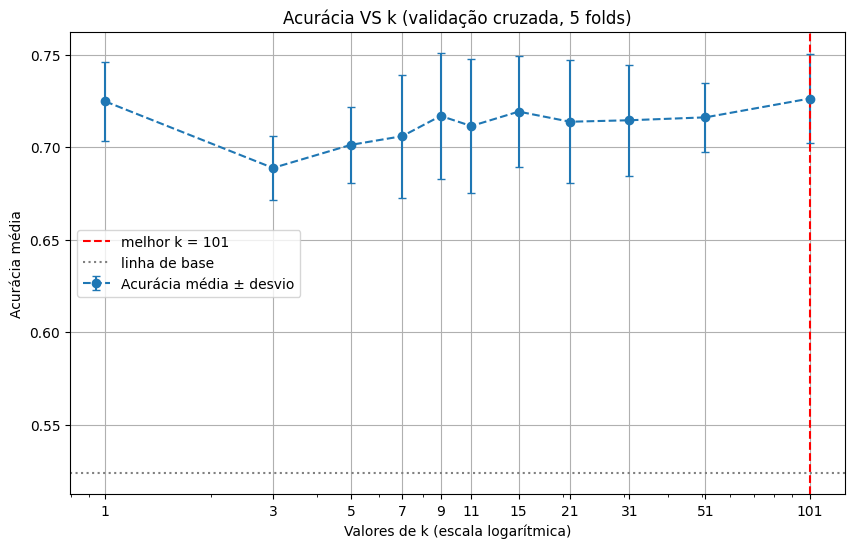

In [9]:
# melhor k = maior acurácia média (em caso de empate, o maior k, que dá o modelo mais suave)
melhor_acc = max(media_acuracia)
melhor_k = max(k for k, m in zip(k_valores, media_acuracia) if abs(m - melhor_acc) < 1e-12)
linha_base = (y_train == 'médio').mean()
print(f'Melhor k: {melhor_k} (acurácia média = {melhor_acc:.4f})')
print(f'Linha de base (prever sempre "médio"): {linha_base:.4f}')

# gráfico: acurácia média ± desvio em função de k
plt.figure(figsize=(10, 6))
plt.errorbar(k_valores, media_acuracia, yerr=desvio_acuracia, marker='o', linestyle='--', capsize=3, label='Acurácia média ± desvio')
plt.axvline(melhor_k, color='red', ls='--', label=f'melhor k = {melhor_k}')
plt.axhline(linha_base, color='gray', ls=':', label='linha de base')
plt.xscale('log')
plt.xticks(k_valores, k_valores)
plt.xlabel('Valores de k (escala logarítmica)')
plt.ylabel('Acurácia média')
plt.title('Acurácia VS k (validação cruzada, 5 folds)')
plt.legend()
plt.grid()
plt.show()

In [10]:
# acurácia no PRÓPRIO treino (sem validação cruzada): mostra o overfitting de k muito baixo
for k in sorted({1, 11, melhor_k}):
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(x_train, y_train)
    print(f'k = {k:>3}: acurácia no próprio treino = {m.score(x_train, y_train):.4f}')

k =   1: acurácia no próprio treino = 1.0000
k =  11: acurácia no próprio treino = 0.7584
k = 101: acurácia no próprio treino = 0.7318


**Resposta.** O k escolhido é o de maior acurácia média na validação cruzada (impresso acima: **k = 101**). Porém **a diferença entre os valores de k é pequena**: o desvio entre os folds (0,02 a 0,04) é maior que a diferença entre quase todos os k, então a partir de k = 7 o desempenho é praticamente o mesmo e a escolha não é conclusiva.

**O que acontece para valores muito baixos e muito altos de k?**
- **k muito baixo (k = 1):** o modelo é sensível demais aos dados de treino e aprende o ruído (**overfitting**, alta variância). Isso aparece na acurácia de 1,0 no próprio treino (cada ponto é o seu próprio vizinho) contra um valor bem menor na validação.
- **k muito alto:** o modelo considera vizinhos demais e perde os padrões locais (**underfitting**, alto viés). No limite, k = N prevê sempre a classe mais frequente ("médio"). Com k = 101 a classe rara *bom* nunca é prevista, porque entre 101 vizinhos ela jamais é maioria.
- O k ideal equilibra os dois comportamentos.

## Tarefa 4 - Avaliação do modelo: utilizando o conjunto de teste, calcule a matriz de confusão e as métricas de acurácia, precisão, recall e F1-score para cada classe. Responda: Entre quais classes o modelo erra com mais frequência?

In [11]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# modelo final: normalização + k-NN com o melhor k, treinado em TODO o treino
knn_final = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=melhor_k))
knn_final.fit(x_train, y_train)

# predição no conjunto de teste (usado só agora)
y_pred = knn_final.predict(x_test)

print(f'k escolhido: {melhor_k}')
print(f'Acurácia no conjunto de teste: {accuracy_score(y_test, y_pred):.4f}')
print(f'Linha de base (sempre "médio"): {(y_test == "médio").mean():.4f}')
print()
# precisão, recall, F1 e suporte de cada classe, além das médias
print(classification_report(y_test, y_pred, labels=ordem, digits=4, zero_division=0))

k escolhido: 101
Acurácia no conjunto de teste: 0.7469
Linha de base (sempre "médio"): 0.5219

              precision    recall  f1-score   support

        ruim     0.7535    0.7181    0.7354       149
       médio     0.7416    0.7904    0.7652       167
         bom     0.0000    0.0000    0.0000         4

    accuracy                         0.7469       320
   macro avg     0.4984    0.5028    0.5002       320
weighted avg     0.7379    0.7469    0.7418       320



            previsto ruim  previsto médio  previsto bom
real ruim             107              42             0
real médio             35             132             0
real bom                0               4             0

Total de erros: 81 | erros entre ruim e médio: 77 (95.1%)


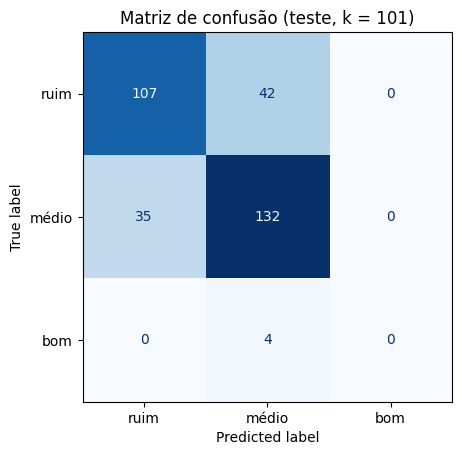

In [12]:
# matriz de confusão (linhas = real, colunas = previsto)
cm = confusion_matrix(y_test, y_pred, labels=ordem)
matriz = pd.DataFrame(cm, index=[f'real {c}' for c in ordem], columns=[f'previsto {c}' for c in ordem])
print(matriz)

# onde estão os erros: total de erros e quantos são entre ruim e médio
erros_total = cm.sum() - np.trace(cm)
erros_ruim_medio = cm[0, 1] + cm[1, 0]
print()
print(f'Total de erros: {erros_total} | erros entre ruim e médio: {erros_ruim_medio} ({erros_ruim_medio / erros_total:.1%})')

ConfusionMatrixDisplay(cm, display_labels=ordem).plot(cmap='Blues', colorbar=False)
plt.grid(False)
plt.title(f'Matriz de confusão (teste, k = {melhor_k})')
plt.show()

Como ler o relatório: `precision` = dos previstos como a classe, quantos eram dela; `recall` = das amostras da classe, quantas foram encontradas; `f1-score` = média harmônica dos dois; `support` = quantidade real de amostras da classe no teste; `macro avg` = média simples entre as classes; `weighted avg` = média ponderada pelo `support`.

**Resposta.** O modelo final (k = 101) atinge acurácia de ≈ 0,75 no teste, acima da linha de base de ≈ 0,52 (prever sempre "médio") e consistente com a validação cruzada. **Entre quais classes o modelo erra mais?** Entre **ruim e médio**: quase todos os erros (≈ 95%) são vinhos ruins classificados como médios e médios classificados como ruins. Faz sentido, porque a fronteira entre elas fica entre as notas 5 e 6, avaliações humanas subjetivas de vinhos quimicamente muito parecidos.

**Observação importante:** a classe **bom** tem precisão, recall e F1 iguais a zero: o modelo nunca a prevê (são só 18 vinhos "bom" na base e 4 no teste). A acurácia global esconde essa falha, e por isso o F1 macro é bem menor que a acurácia. Para detectar vinhos "bom" seria preciso balancear as classes ou usar outra técnica.